In [1]:
import numpy as np
import matplotlib as plt

%load_ext autoreload
%autoreload 2

from a02_helper import *
from a02_functions import (
    sigma,
    logsigma,
    er,
    d_er,
    gd_er,
    sgdepoch_er,
    sgd_er,
    optimize,
)

# 2. Empirical Risk Minimization

## Helper functions

Define the logistic function in `a02_functions.py`. Make sure it operates on both
scalars and vectors. Then test it below.

In [2]:
# this should give:
# [0.5, array([0.26894142, 0.5, 0.73105858])]
[sigma(0), sigma(np.array([-1, 0, 1]))]

[np.float64(0.5), array([0.26894142, 0.5       , 0.73105858])]

Define the logarithm of the logistic function in `a02_functions.py`. Make sure it
operates on both scalars and vectors.

In [3]:
# this should give:
# [-0.69314718055994529, array([-1.31326169, -0.69314718, -0.31326169])]
[logsigma(0), logsigma(np.array([-1, 0, 1]))]

[np.float64(-0.6931471805599453),
 array([-1.31326169, -0.69314718, -0.31326169])]

## 2b Empirical risk and gradient

Complete the function for the empirical risk of the logistic regression model in
`a02_functions.py` and test it below.

In [4]:
# this should give:
# 15.356163676288993
er(y, Xz, np.linspace(-5, 5, D))

np.float64(15.356163676288997)

Now fill out the function that returns the gradient of the empirical risk of the
logistic regression model in `a02_functions.py`, and test it below.

In [5]:
# this should give:
# array([-0.1798825 , -0.04693023, -0.27466027, -0.05118185, -0.26186368,
#        -0.25969397, -0.3003884 , -0.20292501, -0.21506925, -0.15360933,
#        -0.25165549, -0.11497659, -0.14866875, -0.07646526, -0.18350882,
#        -0.28216633, -0.25683434, -0.21190226, -0.29450173, -0.17748953,
#        -0.38329083, -0.03926913, -0.27393521, -0.20662464,  0.23056057,
#         0.20561304,  0.18575698,  0.17210766,  0.11730408,  0.1555117 ,
#         0.1342924 ,  0.12238809,  0.11268253,  0.12274729,  0.13289319,
#         0.14885237,  0.19473723,  0.03522699,  0.12881622,  0.07477366,
#         0.09411536,  0.11815139,  0.1471057 ,  0.09038803,  0.13539737,
#         0.14756532,  0.05466443,  0.08838642,  0.08228431,  0.11671288,
#         0.08454313, -0.13649572, -0.19724037, -0.01406327, -0.04967132,
#        -0.12338248, -0.1357652 ])
d_er(y, Xz, np.linspace(-5, 5, D))

array([-0.1798825 , -0.04693023, -0.27466027, -0.05118185, -0.26186368,
       -0.25969397, -0.3003884 , -0.20292501, -0.21506925, -0.15360933,
       -0.25165549, -0.11497659, -0.14866875, -0.07646526, -0.18350882,
       -0.28216633, -0.25683434, -0.21190226, -0.29450173, -0.17748953,
       -0.38329083, -0.03926913, -0.27393521, -0.20662464,  0.23056057,
        0.20561304,  0.18575698,  0.17210766,  0.11730408,  0.1555117 ,
        0.1342924 ,  0.12238809,  0.11268253,  0.12274729,  0.13289319,
        0.14885237,  0.19473723,  0.03522699,  0.12881622,  0.07477366,
        0.09411536,  0.11815139,  0.1471057 ,  0.09038803,  0.13539737,
        0.14756532,  0.05466443,  0.08838642,  0.08228431,  0.11671288,
        0.08454313, -0.13649572, -0.19724037, -0.01406327, -0.04967132,
       -0.12338248, -0.1357652 ])

## 2c Gradient descent

In `a02_functions.py`, define the objective and update function for one
gradient-descent epoch for fitting an MLE estimate of logistic regression with
gradient descent (should return a tuple of two functions; see `optimize` in
`a02_functions.py`). Then test it below.

In [6]:
# this should give
# [15.356163676288993,
#  array([-4.98486859, -5.00348273, -4.97957969, -4.99464192, -4.98028549,
#         -4.97881798, -4.97516411, -4.98255264, -4.97950841, -4.98353035,
#         -4.97505258, -4.99343004, -4.98739394, -4.991352  , -4.97951014,
#         -4.97641948, -4.97550312, -4.98109859, -4.97826941, -4.98042354,
#         -4.96918027, -4.98940344, -4.97057868, -4.980086  , -5.00671666,
#         -5.00338624, -5.01360572, -4.9991855 , -4.99962596, -4.9990924 ,
#         -4.99728516, -4.99710625, -5.00490407, -4.99711359, -4.99844041,
#         -4.99879209, -5.00255707, -4.99927668, -5.00020121, -4.99270287,
#         -5.00059118, -5.00229197, -4.9975015 , -5.00292195, -5.00493102,
#         -5.00724744, -4.99867731, -5.00170438, -4.99836863, -4.99853799,
#         -4.9994118 , -4.98326416, -4.97266254, -4.99221473, -4.98906378,
#         -4.98190217, -4.97744729])]
f, update = gd_er(y, Xz)
[f(np.linspace(-5, 5, D)), update(np.linspace(-5, -5, D), 0.1)]

[np.float64(15.356163676288997),
 array([-4.98486859, -5.00348273, -4.97957969, -4.99464192, -4.98028549,
        -4.97881798, -4.97516411, -4.98255264, -4.97950841, -4.98353035,
        -4.97505258, -4.99343004, -4.98739394, -4.991352  , -4.97951014,
        -4.97641948, -4.97550312, -4.98109859, -4.97826941, -4.98042354,
        -4.96918027, -4.98940344, -4.97057868, -4.980086  , -5.00671666,
        -5.00338624, -5.01360572, -4.9991855 , -4.99962596, -4.9990924 ,
        -4.99728516, -4.99710625, -5.00490407, -4.99711359, -4.99844041,
        -4.99879209, -5.00255707, -4.99927668, -5.00020121, -4.99270287,
        -5.00059118, -5.00229197, -4.9975015 , -5.00292195, -5.00493102,
        -5.00724744, -4.99867731, -5.00170438, -4.99836863, -4.99853799,
        -4.9994118 , -4.98326416, -4.97266254, -4.99221473, -4.98906378,
        -4.98190217, -4.97744729])]

In [7]:
# Now you can run gradient descent!
np.random.seed(0)
w0 = np.random.normal(size=D)
wz_gd, vz_gd, ez_gd = optimize(gd_er(y, Xz), w0, nepochs=500)

Epoch   0: f=     2.165, eps=0.010000000
Epoch   1: f=     2.161, eps=0.010500000
Epoch   2: f=     2.157, eps=0.011025000
Epoch   3: f=     2.153, eps=0.011576250
Epoch   4: f=     2.148, eps=0.012155063
Epoch   5: f=     2.143, eps=0.012762816
Epoch   6: f=     2.138, eps=0.013400956
Epoch   7: f=     2.133, eps=0.014071004
Epoch   8: f=     2.128, eps=0.014774554
Epoch   9: f=     2.122, eps=0.015513282
Epoch  10: f=     2.116, eps=0.016288946
Epoch  11: f=     2.110, eps=0.017103394
Epoch  12: f=     2.104, eps=0.017958563
Epoch  13: f=     2.098, eps=0.018856491
Epoch  14: f=     2.091, eps=0.019799316
Epoch  15: f=     2.084, eps=0.020789282
Epoch  16: f=     2.076, eps=0.021828746
Epoch  17: f=     2.069, eps=0.022920183
Epoch  18: f=     2.061, eps=0.024066192
Epoch  19: f=     2.052, eps=0.025269502
Epoch  20: f=     2.044, eps=0.026532977
Epoch  21: f=     2.035, eps=0.027859626
Epoch  22: f=     2.025, eps=0.029252607
Epoch  23: f=     2.016, eps=0.030715238
Epoch  24: f=   

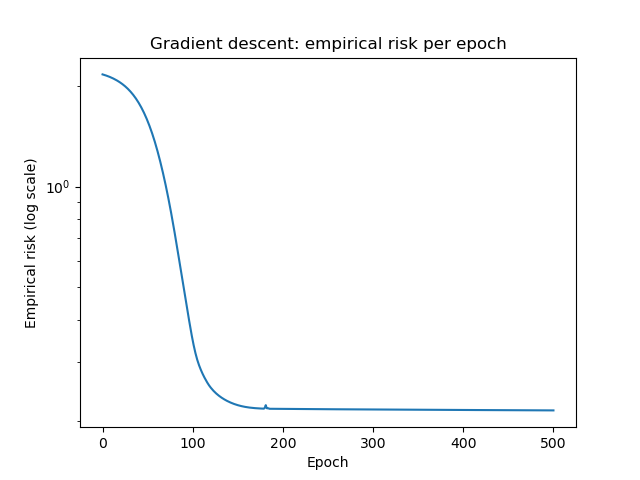

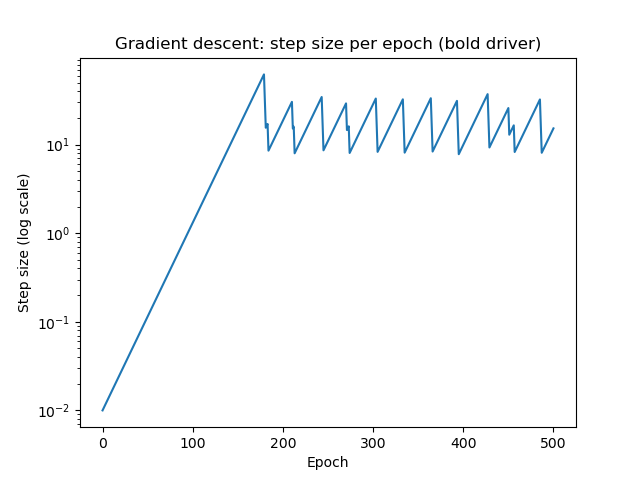

epoch   0: risk 2.1652, step size 0.01
epoch  10: risk 2.1165, step size 0.01629
epoch  50: risk 1.5697, step size 0.1147
epoch 100: risk 0.3466, step size 1.315
epoch 200: risk 0.2167, step size 18.67
epoch 300: risk 0.2158, step size 28.63
epoch 500: risk 0.2145, step size 15.26
epochs in which the risk went up (step size halved): 23
norm of the gradient at the end: 0.0005757343249670458


In [8]:
# look at how gradient descent made progess
# YOUR CODE HERE
# Empirical risk per epoch (log scale) and the step size chosen by the bold driver
nextplot()
plt.semilogy(vz_gd)
plt.xlabel("Epoch")
plt.ylabel("Empirical risk (log scale)")
plt.title("Gradient descent: empirical risk per epoch")
plt.show()

nextplot()
plt.semilogy(ez_gd)
plt.xlabel("Epoch")
plt.ylabel("Step size (log scale)")
plt.title("Gradient descent: step size per epoch (bold driver)")
plt.show()

for e in [0, 10, 50, 100, 200, 300, 500]:
    print(f"epoch {e:3d}: risk {vz_gd[e]:.4f}, step size {ez_gd[e]:.4g}")
print("epochs in which the risk went up (step size halved):", np.sum(np.diff(vz_gd) > 0))
print("norm of the gradient at the end:", np.linalg.norm(d_er(y, Xz, wz_gd)))

## 2d Stochastic gradient descent

Implement stochastic gradient descent in `a02_functions.py`. Then test it with the
given results below.

In [9]:
# when you run this multiple times, with 50% probability you should get the
# following result (there is one other result which is very close):
# array([ -3.43689655e+02,  -1.71161311e+02,  -5.71093536e+02,
#         -5.16478220e+01,   4.66294348e+02,  -3.71589878e+02,
#          5.21493183e+02,   1.25699230e+03,   8.33804130e+02,
#          5.63185399e+02,   1.32761302e+03,  -2.64104011e+02,
#          7.10693307e+02,  -1.75497331e+02,  -1.94174427e+02,
#          1.11641507e+02,  -3.30817509e+02,  -3.46754913e+02,
#          8.48722111e+02,  -1.89136304e+02,  -4.25693844e+02,
#         -1.23084189e+02,  -2.95894797e+02,  -2.35789333e+02,
#         -3.38695243e+02,  -3.05642830e+02,  -2.28975383e+02,
#         -2.38075137e+02,  -1.66702530e+02,  -2.27341599e+02,
#         -1.77575620e+02,  -1.49093855e+02,  -1.70028859e+02,
#         -1.50243833e+02,  -1.82986008e+02,  -2.41143708e+02,
#         -3.31047159e+02,  -5.79991185e+01,  -1.98477863e+02,
#         -1.91264948e+02,  -1.17371919e+02,  -1.66953779e+02,
#         -2.01472565e+02,  -1.23330949e+02,  -3.00857740e+02,
#         -1.95853348e+02,  -7.44868073e+01,  -1.11172370e+02,
#         -1.57618226e+02,  -1.25729512e+00,  -1.45536466e+02,
#         -1.43362438e+02,  -3.00429708e+02,  -9.84391082e+01,
#         -4.54152047e+01,  -5.26492232e+01,  -1.45175427e+02])
sgdepoch_er(y[1:3], Xz[1:3, :], np.linspace(-5, 5, D), 1000)

array([-3.43689655e+02, -1.71161311e+02, -5.71093536e+02, -5.16478220e+01,
        4.66294348e+02, -3.71589878e+02,  5.21493183e+02,  1.25699230e+03,
        8.33804130e+02,  5.63185399e+02,  1.32761302e+03, -2.64104011e+02,
        7.10693307e+02, -1.75497331e+02, -1.94174427e+02,  1.11641507e+02,
       -3.30817509e+02, -3.46754913e+02,  8.48722111e+02, -1.89136304e+02,
       -4.25693844e+02, -1.23084189e+02, -2.95894797e+02, -2.35789333e+02,
       -3.38695243e+02, -3.05642830e+02, -2.28975383e+02, -2.38075137e+02,
       -1.66702530e+02, -2.27341599e+02, -1.77575620e+02, -1.49093855e+02,
       -1.70028859e+02, -1.50243833e+02, -1.82986008e+02, -2.41143708e+02,
       -3.31047159e+02, -5.79991185e+01, -1.98477863e+02, -1.91264948e+02,
       -1.17371919e+02, -1.66953779e+02, -2.01472565e+02, -1.23330949e+02,
       -3.00857740e+02, -1.95853348e+02, -7.44868073e+01, -1.11172370e+02,
       -1.57618226e+02, -1.25729512e+00, -1.45536466e+02, -1.43362438e+02,
       -3.00429708e+02, -

In [10]:
# with 50% probability, you should get:
# [20.43248652284754,
#  array([ -3.43689655e+02,  -1.71161311e+02,  -5.71093536e+02,
#          -5.16478220e+01,   4.66294348e+02,  -3.71589878e+02,
#           5.21493183e+02,   1.25699230e+03,   8.33804130e+02,
#           5.63185399e+02,   1.32761302e+03,  -2.64104011e+02,
#           7.10693307e+02,  -1.75497331e+02,  -1.94174427e+02,
#           1.11641507e+02,  -3.30817509e+02,  -3.46754913e+02,
#           8.48722111e+02,  -1.89136304e+02,  -4.25693844e+02,
#          -1.23084189e+02,  -2.95894797e+02,  -2.35789333e+02,
#          -3.38695243e+02,  -3.05642830e+02,  -2.28975383e+02,
#          -2.38075137e+02,  -1.66702530e+02,  -2.27341599e+02,
#          -1.77575620e+02,  -1.49093855e+02,  -1.70028859e+02,
#          -1.50243833e+02,  -1.82986008e+02,  -2.41143708e+02,
#          -3.31047159e+02,  -5.79991185e+01,  -1.98477863e+02,
#          -1.91264948e+02,  -1.17371919e+02,  -1.66953779e+02,
#          -2.01472565e+02,  -1.23330949e+02,  -3.00857740e+02,
#          -1.95853348e+02,  -7.44868073e+01,  -1.11172370e+02,
#          -1.57618226e+02,  -1.25729512e+00,  -1.45536466e+02,
#          -1.43362438e+02,  -3.00429708e+02,  -9.84391082e+01,
#          -4.54152047e+01,  -5.26492232e+01,  -1.45175427e+02])]
f, update = sgd_er(y[1:3], Xz[1:3, :])
[f(np.linspace(-5, 5, D)), update(np.linspace(-5, 5, D), 1000)]

[np.float64(20.432486522847544),
 array([-3.43689655e+02, -1.71161311e+02, -5.71093536e+02, -5.16478220e+01,
         4.66294348e+02, -3.71589878e+02,  5.21493183e+02,  1.25699230e+03,
         8.33804130e+02,  5.63185399e+02,  1.32761302e+03, -2.64104011e+02,
         7.10693307e+02, -1.75497331e+02, -1.94174427e+02,  1.11641507e+02,
        -3.30817509e+02, -3.46754913e+02,  8.48722111e+02, -1.89136304e+02,
        -4.25693844e+02, -1.23084189e+02, -2.95894797e+02, -2.35789333e+02,
        -3.38695243e+02, -3.05642830e+02, -2.28975383e+02, -2.38075137e+02,
        -1.66702530e+02, -2.27341599e+02, -1.77575620e+02, -1.49093855e+02,
        -1.70028859e+02, -1.50243833e+02, -1.82986008e+02, -2.41143708e+02,
        -3.31047159e+02, -5.79991185e+01, -1.98477863e+02, -1.91264948e+02,
        -1.17371919e+02, -1.66953779e+02, -2.01472565e+02, -1.23330949e+02,
        -3.00857740e+02, -1.95853348e+02, -7.44868073e+01, -1.11172370e+02,
        -1.57618226e+02, -1.25729512e+00, -1.45536466e+

In [11]:
# you can run stochastic gradient descent!
wz_sgd, vz_sgd, ez_sgd = optimize(sgd_er(y, Xz), w0, nepochs=500)

Epoch   0: f=     2.165, eps=0.010000000
Epoch   1: f=     0.313, eps=0.010500000
Epoch   2: f=     0.257, eps=0.011025000
Epoch   3: f=     0.241, eps=0.011576250
Epoch   4: f=     0.234, eps=0.012155063
Epoch   5: f=     0.231, eps=0.012762816
Epoch   6: f=     0.227, eps=0.013400956
Epoch   7: f=     0.229, eps=0.006700478
Epoch   8: f=     0.224, eps=0.007035502
Epoch   9: f=     0.223, eps=0.007387277
Epoch  10: f=     0.223, eps=0.003693639
Epoch  11: f=     0.222, eps=0.003878321
Epoch  12: f=     0.222, eps=0.004072237
Epoch  13: f=     0.221, eps=0.004275848
Epoch  14: f=     0.221, eps=0.004489641
Epoch  15: f=     0.221, eps=0.004714123
Epoch  16: f=     0.221, eps=0.004949829
Epoch  17: f=     0.221, eps=0.002474914
Epoch  18: f=     0.220, eps=0.002598660
Epoch  19: f=     0.220, eps=0.002728593
Epoch  20: f=     0.220, eps=0.002865023
Epoch  21: f=     0.220, eps=0.003008274
Epoch  22: f=     0.220, eps=0.003158688
Epoch  23: f=     0.220, eps=0.003316622
Epoch  24: f=   

Epoch  34: f=     0.219, eps=0.002701214
Epoch  35: f=     0.219, eps=0.002836275
Epoch  36: f=     0.219, eps=0.002978088
Epoch  37: f=     0.219, eps=0.003126993
Epoch  38: f=     0.219, eps=0.003283342
Epoch  39: f=     0.218, eps=0.003447510


Epoch  40: f=     0.218, eps=0.003619885
Epoch  41: f=     0.218, eps=0.003800879
Epoch  42: f=     0.218, eps=0.003990923
Epoch  43: f=     0.218, eps=0.001995462
Epoch  44: f=     0.218, eps=0.002095235
Epoch  45: f=     0.218, eps=0.002199996
Epoch  46: f=     0.218, eps=0.001099998
Epoch  47: f=     0.218, eps=0.001154998
Epoch  48: f=     0.218, eps=0.001212748
Epoch  49: f=     0.218, eps=0.001273385
Epoch  50: f=     0.218, eps=0.001337055
Epoch  51: f=     0.218, eps=0.001403907
Epoch  52: f=     0.218, eps=0.001474103
Epoch  53: f=     0.218, eps=0.001547808
Epoch  54: f=     0.218, eps=0.001625198
Epoch  55: f=     0.218, eps=0.001706458
Epoch  56: f=     0.218, eps=0.001791781
Epoch  57: f=     0.218, eps=0.001881370
Epoch  58: f=     0.218, eps=0.001975439
Epoch  59: f=     0.218, eps=0.002074211
Epoch  60: f=     0.218, eps=0.002177921
Epoch  61: f=     0.218, eps=0.002286817
Epoch  62: f=     0.218, eps=0.002401158
Epoch  63: f=     0.218, eps=0.002521216
Epoch  64: f=   

Epoch  74: f=     0.218, eps=0.000977808
Epoch  75: f=     0.218, eps=0.001026699
Epoch  76: f=     0.218, eps=0.001078034
Epoch  77: f=     0.218, eps=0.001131935
Epoch  78: f=     0.218, eps=0.001188532
Epoch  79: f=     0.218, eps=0.001247959


Epoch  80: f=     0.218, eps=0.001310357
Epoch  81: f=     0.218, eps=0.001375875
Epoch  82: f=     0.218, eps=0.001444668
Epoch  83: f=     0.218, eps=0.001516902
Epoch  84: f=     0.218, eps=0.001592747
Epoch  85: f=     0.218, eps=0.001672384
Epoch  86: f=     0.217, eps=0.001756003
Epoch  87: f=     0.217, eps=0.001843804
Epoch  88: f=     0.217, eps=0.001935994
Epoch  89: f=     0.217, eps=0.002032793
Epoch  90: f=     0.217, eps=0.002134433
Epoch  91: f=     0.217, eps=0.002241155
Epoch  92: f=     0.217, eps=0.002353213
Epoch  93: f=     0.217, eps=0.002470873
Epoch  94: f=     0.217, eps=0.001235437
Epoch  95: f=     0.217, eps=0.001297208
Epoch  96: f=     0.217, eps=0.001362069
Epoch  97: f=     0.217, eps=0.001430172
Epoch  98: f=     0.217, eps=0.001501681
Epoch  99: f=     0.217, eps=0.001576765
Epoch 100: f=     0.217, eps=0.001655603
Epoch 101: f=     0.217, eps=0.001738383
Epoch 102: f=     0.217, eps=0.001825303
Epoch 103: f=     0.217, eps=0.000912651
Epoch 104: f=   

Epoch 114: f=     0.217, eps=0.001560943
Epoch 115: f=     0.217, eps=0.000780472
Epoch 116: f=     0.217, eps=0.000819495
Epoch 117: f=     0.217, eps=0.000860470
Epoch 118: f=     0.217, eps=0.000903494
Epoch 119: f=     0.217, eps=0.000948668


... (15 outputs left out)

Epoch 433: f=     0.217, eps=0.000731053
Epoch 434: f=     0.217, eps=0.000767606
Epoch 435: f=     0.217, eps=0.000805986
Epoch 436: f=     0.217, eps=0.000846286
Epoch 437: f=     0.217, eps=0.000888600
Epoch 438: f=     0.217, eps=0.000933030


Epoch 439: f=     0.217, eps=0.000979681
Epoch 440: f=     0.217, eps=0.000489841
Epoch 441: f=     0.216, eps=0.000514333
Epoch 442: f=     0.216, eps=0.000540049
Epoch 443: f=     0.216, eps=0.000567052
Epoch 444: f=     0.216, eps=0.000595404
Epoch 445: f=     0.216, eps=0.000625175
Epoch 446: f=     0.216, eps=0.000656433
Epoch 447: f=     0.216, eps=0.000689255
Epoch 448: f=     0.216, eps=0.000723718
Epoch 449: f=     0.216, eps=0.000759904
Epoch 450: f=     0.216, eps=0.000797899
Epoch 451: f=     0.216, eps=0.000837794
Epoch 452: f=     0.216, eps=0.000879684
Epoch 453: f=     0.216, eps=0.000923668
Epoch 454: f=     0.216, eps=0.000969851
Epoch 455: f=     0.216, eps=0.001018344
Epoch 456: f=     0.216, eps=0.000509172
Epoch 457: f=     0.216, eps=0.000534630
Epoch 458: f=     0.216, eps=0.000561362
Epoch 459: f=     0.216, eps=0.000589430
Epoch 460: f=     0.216, eps=0.000618902
Epoch 461: f=     0.216, eps=0.000649847
Epoch 462: f=     0.216, eps=0.000682339
Epoch 463: f=   

Epoch 472: f=     0.216, eps=0.001111458
Epoch 473: f=     0.216, eps=0.001167031
Epoch 474: f=     0.216, eps=0.001225383
Epoch 475: f=     0.216, eps=0.001286652
Epoch 476: f=     0.216, eps=0.001350984
Epoch 477: f=     0.216, eps=0.000675492
Epoch 478: f=     0.216, eps=0.000709267


Epoch 479: f=     0.216, eps=0.000744730
Epoch 480: f=     0.216, eps=0.000781967
Epoch 481: f=     0.216, eps=0.000821065
Epoch 482: f=     0.216, eps=0.000862118
Epoch 483: f=     0.216, eps=0.000905224
Epoch 484: f=     0.216, eps=0.000950485
Epoch 485: f=     0.216, eps=0.000998010
Epoch 486: f=     0.216, eps=0.001047910
Epoch 487: f=     0.216, eps=0.001100306
Epoch 488: f=     0.216, eps=0.001155321
Epoch 489: f=     0.216, eps=0.000577660
Epoch 490: f=     0.216, eps=0.000606543
Epoch 491: f=     0.216, eps=0.000636871
Epoch 492: f=     0.216, eps=0.000668714
Epoch 493: f=     0.216, eps=0.000702150
Epoch 494: f=     0.216, eps=0.000737257
Epoch 495: f=     0.216, eps=0.000774120
Epoch 496: f=     0.216, eps=0.000812826
Epoch 497: f=     0.216, eps=0.000853468
Epoch 498: f=     0.216, eps=0.000896141
Epoch 499: f=     0.216, eps=0.000940948
Result after 500 epochs: f=0.21641184695591562


## 2e Compare GD and SGD

Explore the behavior of both methods, given the parameters provided to you!

estimated minimum of the empirical risk R* = 0.20475
time per epoch: GD 0.09 ms, SGD 5.3 ms (57x)


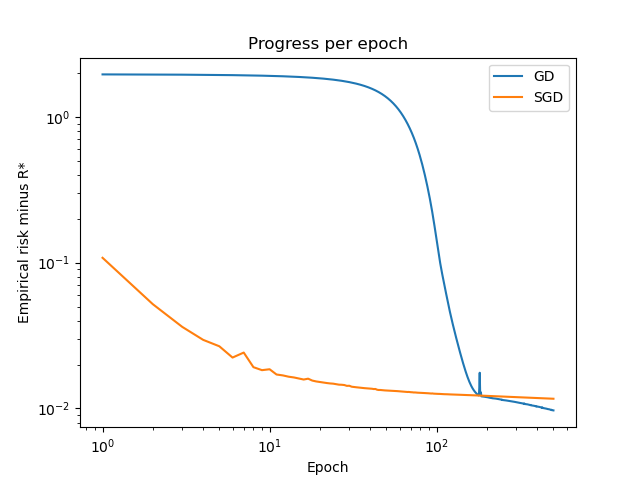

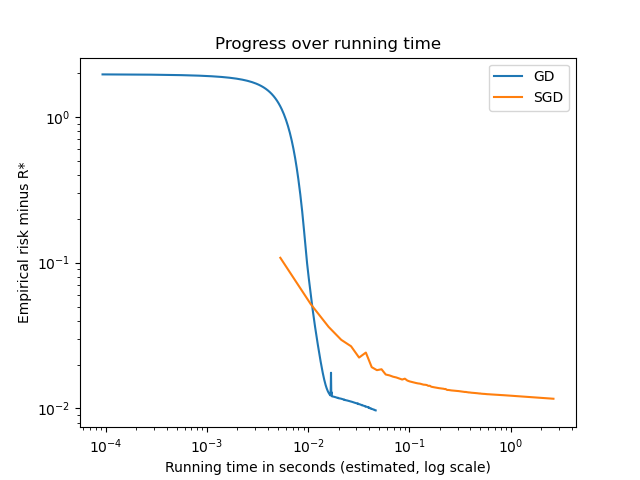

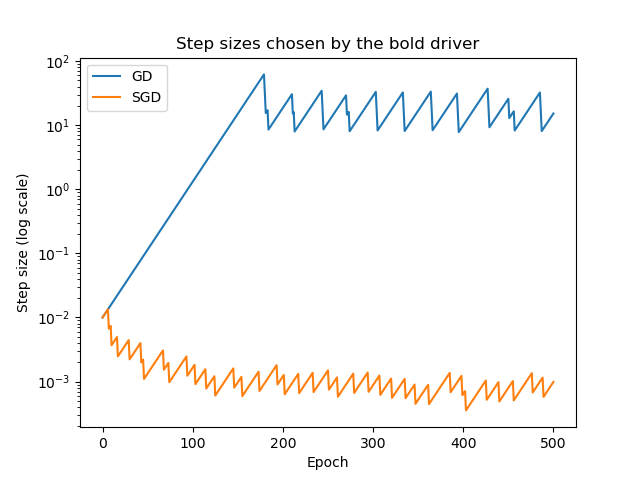

                   final risk  epoch risk <= 1.10 R*  epoch risk <= 1.05 R*  train accuracy  test accuracy  test log loss  norm of w  steps halved
GD (500 epochs)        0.2145                  144.0                  414.0          0.9217         0.9186         0.2792     8.9448          23.0
SGD (500 epochs)       0.2164                    8.0                    NaN          0.9214         0.9173         0.2827     6.7603          36.0
GD (30000 epochs)      0.2048                    NaN                    NaN          0.9233         0.9271         0.2698    50.0984           NaN


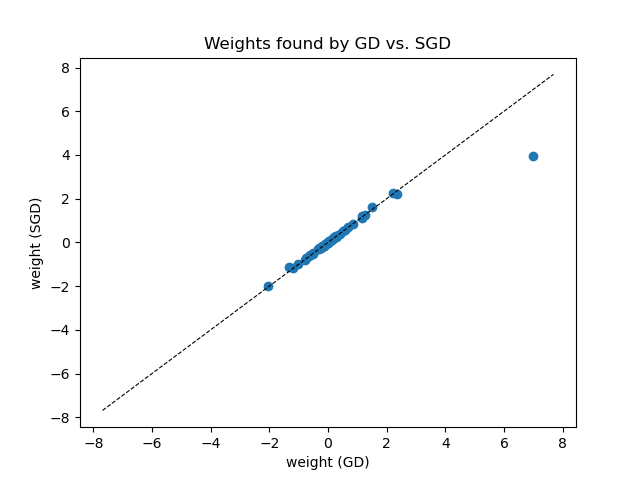

correlation of the weight vectors: 0.9619


SGD seed 1: risk after 1 epoch 0.3203, after 500 epochs 0.21639, final step size 0.00099


SGD seed 2: risk after 1 epoch 0.3212, after 500 epochs 0.21638, final step size 0.00099


SGD seed 3: risk after 1 epoch 0.3142, after 500 epochs 0.21642, final step size 0.00099


In [12]:
# YOUR CODE HERE
import time

# Reference point: run GD for many more epochs to estimate the minimal empirical risk R*
# (about 3 seconds; sklearn's LogisticRegression without penalty and bias gives the same value)
wz_ref, vz_ref, _ = optimize(gd_er(y, Xz), w0, nepochs=30000, verbose=False)
r_star = vz_ref[-1]
print(f"estimated minimum of the empirical risk R* = {r_star:.5f}")

# Cost of one epoch: GD computes one full gradient, SGD performs N single-example updates
f_gd, upd_gd = gd_er(y, Xz)
f_sgd, upd_sgd = sgd_er(y, Xz)
t = time.perf_counter()
[upd_gd(w0, 0.01) for _ in range(50)]
t_gd = (time.perf_counter() - t) / 50
t = time.perf_counter()
[upd_sgd(w0, 0.01) for _ in range(5)]
t_sgd = (time.perf_counter() - t) / 5
print(f"time per epoch: GD {1000 * t_gd:.2f} ms, SGD {1000 * t_sgd:.1f} ms ({t_sgd / t_gd:.0f}x)")

# 1) Risk per epoch (distance to R*, log-log scale to see the early phase as well)
epochs = np.arange(1, len(vz_gd))
nextplot()
plt.loglog(epochs, vz_gd[1:] - r_star, label="GD")
plt.loglog(epochs, vz_sgd[1:] - r_star, label="SGD")
plt.xlabel("Epoch")
plt.ylabel("Empirical risk minus R*")
plt.title("Progress per epoch")
plt.legend()
plt.show()

# 2) Risk over (estimated) running time
nextplot()
plt.loglog(epochs * t_gd, vz_gd[1:] - r_star, label="GD")
plt.loglog(epochs * t_sgd, vz_sgd[1:] - r_star, label="SGD")
plt.xlabel("Running time in seconds (estimated, log scale)")
plt.ylabel("Empirical risk minus R*")
plt.title("Progress over running time")
plt.legend()
plt.show()

# 3) Step sizes chosen by the bold driver
nextplot()
plt.semilogy(ez_gd, label="GD")
plt.semilogy(ez_sgd, label="SGD")
plt.xlabel("Epoch")
plt.ylabel("Step size (log scale)")
plt.title("Step sizes chosen by the bold driver")
plt.legend()
plt.show()

# 4) Summary of the fitted models
def accuracy(Xs, ys, w):
    return np.mean((Xs @ w > 0) == ys)


def first_epoch_within(v, tol):
    """First epoch with risk at most (1 + tol) * R*, or None."""
    idx = np.where(v <= (1 + tol) * r_star)[0]
    return int(idx[0]) if len(idx) > 0 else None


summary = pd.DataFrame(
    {
        "final risk": [vz_gd[-1], vz_sgd[-1], r_star],
        "epoch risk <= 1.10 R*": [first_epoch_within(vz_gd, 0.10), first_epoch_within(vz_sgd, 0.10), None],
        "epoch risk <= 1.05 R*": [first_epoch_within(vz_gd, 0.05), first_epoch_within(vz_sgd, 0.05), None],
        "train accuracy": [accuracy(Xz, y, w) for w in [wz_gd, wz_sgd, wz_ref]],
        "test accuracy": [accuracy(Xtestz, ytest, w) for w in [wz_gd, wz_sgd, wz_ref]],
        "test log loss": [er(ytest, Xtestz, w) for w in [wz_gd, wz_sgd, wz_ref]],
        "norm of w": [np.linalg.norm(w) for w in [wz_gd, wz_sgd, wz_ref]],
        "steps halved": [np.sum(np.diff(vz_gd) > 0), np.sum(np.diff(vz_sgd) > 0), None],
    },
    index=["GD (500 epochs)", "SGD (500 epochs)", "GD (30000 epochs)"],
)
print(summary.round(4).to_string())

# 5) Do both methods find the same weights?
nextplot()
plt.scatter(wz_gd, wz_sgd)
lim = np.abs(np.concatenate([wz_gd, wz_sgd])).max() * 1.1
plt.plot([-lim, lim], [-lim, lim], "k--", linewidth=0.8)
plt.xlabel("weight (GD)")
plt.ylabel("weight (SGD)")
plt.title("Weights found by GD vs. SGD")
plt.show()
print("correlation of the weight vectors:", np.corrcoef(wz_gd, wz_sgd)[0, 1].round(4))

# 6) SGD is random: repeat it with different seeds
for seed in [1, 2, 3]:
    np.random.seed(seed)
    _, v, e = optimize(sgd_er(y, Xz), w0, nepochs=500, verbose=False)
    print(f"SGD seed {seed}: risk after 1 epoch {v[1]:.4f}, after 500 epochs {v[-1]:.5f}, final step size {e[-1]:.2g}")